# 03 — Evaluasi dan Temu Kembali Citra
Notebook ini menghitung ulang seluruh metrik model terbaik **langsung dari model tersimpan**:
- Klasifikasi: confusion matrix, TP/TN/FP/FN, presisi, recall, F1, akurasi, specificity, AUC (format tabel template).
- Temu kembali: kueri = data uji, galeri = data latih, kemiripan *cosine*; metrik P@1, P@5, P@10, mAP@10, mAP.
- Contoh hasil temu kembali dan **relevance feedback** (Rocchio).

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

PROJECT = Path.cwd().parent                      # folder "Tugas Temu Kembali Citra"
RAW_DIR = PROJECT / "data pneumonia" / "chest_xray"
DATA_DIR = PROJECT / "data"                      # split dan cache citra hasil persiapan data
OUTPUTS = PROJECT / "outputs"                    # model dan hasil eksperimen
HASIL = Path("hasil")                            # keluaran notebook (terpisah dari outputs/)
HASIL.mkdir(exist_ok=True)
CLASSES = ["Normal", "Bacteria", "Virus"]
NAMA_KELAS = {"Normal": "Normal", "Bacteria": "Pneumonia Bakteri", "Virus": "Pneumonia Virus"}
print("Folder project:", PROJECT)

Folder project: C:\Users\LENOVO\Documents\Temu Kembali Citra\Tugas\Tugas Temu Kembali Citra


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import confusion_matrix, roc_auc_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TF = transforms.Compose([transforms.Resize((224, 224)), transforms.Grayscale(3), transforms.ToTensor(),
                         transforms.Normalize(MEAN, STD)])

class XrayDataset(Dataset):
    def __init__(self, df, cache_sub):
        self.paths = [DATA_DIR / "cache" / cache_sub / n for n in df["cache_name"]]
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return TF(Image.open(self.paths[i]).convert("L"))

class RetrievalNet(nn.Module):
    def __init__(self, arch):
        super().__init__()
        pool = [nn.AdaptiveAvgPool2d(1), nn.Flatten()]
        if arch == "mobilenet_v2":
            self.backbone, dim = nn.Sequential(models.mobilenet_v2().features, *pool), 1280
        elif arch == "efficientnet_b0":
            self.backbone, dim = nn.Sequential(models.efficientnet_b0().features, *pool), 1280
        else:
            self.backbone, dim = nn.Sequential(models.densenet121().features, nn.ReLU(), *pool), 1024
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim, 3))
    def embed(self, x):
        return self.backbone(x)

## 1. Memuat model terbaik dan mengekstraksi embedding

In [3]:
best = json.loads((OUTPUTS / "best_run.json").read_text())
run_name = f"{best['scenario']}__{best['model']}" + (f"__{best['tag']}" if best["tag"] else "")
cache_sub = "clahe" if best["scenario"] == "s3_clahe_augment" else "original"
model = RetrievalNet(best["model"]).to(DEVICE).eval()
model.load_state_dict(torch.load(OUTPUTS / "runs" / run_name / "best.pt", map_location=DEVICE, weights_only=True))
print("Model:", run_name)

splits = pd.read_csv(DATA_DIR / "splits.csv")
train = splits[splits.split == "train"].reset_index(drop=True)
test = splits[splits.split == "test"].reset_index(drop=True)

@torch.no_grad()
def extract(df):
    embs, probs = [], []
    for x in DataLoader(XrayDataset(df, cache_sub), batch_size=64):
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            e = model.embed(x.to(DEVICE)); p = model.head(e).float().softmax(1)
        embs.append(e.float().cpu()); probs.append(p.cpu())
    return torch.cat(embs).numpy(), torch.cat(probs).numpy()

g_emb, _ = extract(train)
q_emb, q_prob = extract(test)
g_lab, q_lab = train["label_idx"].to_numpy(), test["label_idx"].to_numpy()
print("Galeri:", g_emb.shape, "| Kueri:", q_emb.shape)

Model: s2_augment__densenet121__seed7


Galeri: (4030, 1024) | Kueri: (915, 1024)


## 2. Evaluasi klasifikasi (format tabel template)

Akurasi: 80.11% | Macro F1: 80.78% | Macro AUC: 91.87%


,Kelas,TP,TN,FP,FN,(%) Presisi,(%) Recall,(%) F1,(%) Akurasi,(%) Specificity,AUC,Support
0,Normal,226,664,16,9,93.39,96.17,94.76,97.27,97.65,1.00,235
1,Pneumonia Bakteri,322,429,61,103,84.07,75.76,79.70,82.08,87.55,0.90,425
2,Pneumonia Virus,185,555,105,70,63.79,72.55,67.89,80.87,84.09,0.86,255


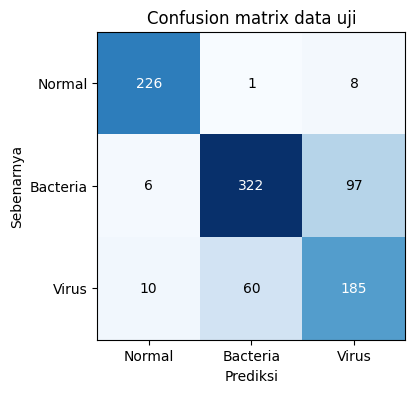

In [4]:
pred = q_prob.argmax(1)
cm = confusion_matrix(q_lab, pred)
rows = []
for c, name in enumerate(CLASSES):
    tp = cm[c, c]; fp = cm[:, c].sum() - tp; fn = cm[c, :].sum() - tp; tn = cm.sum() - tp - fp - fn
    pr, rc = tp / (tp + fp), tp / (tp + fn)
    rows.append({"Kelas": NAMA_KELAS[name], "TP": tp, "TN": tn, "FP": fp, "FN": fn, "(%) Presisi": pr * 100,
                 "(%) Recall": rc * 100, "(%) F1": 200 * pr * rc / (pr + rc), "(%) Akurasi": (tp + tn) / cm.sum() * 100,
                 "(%) Specificity": tn / (tn + fp) * 100, "AUC": roc_auc_score(q_lab == c, q_prob[:, c]),
                 "Support": cm[c].sum()})
per_kelas = pd.DataFrame(rows).round(2)
print(f"Akurasi: {(pred == q_lab).mean()*100:.2f}% | Macro F1: {per_kelas['(%) F1'].mean():.2f}% | "
      f"Macro AUC: {roc_auc_score(q_lab, q_prob, multi_class='ovr')*100:.2f}%")
display(per_kelas)

plt.figure(figsize=(4.5, 4)); plt.imshow(cm, cmap="Blues")
plt.xticks(range(3), CLASSES); plt.yticks(range(3), CLASSES); plt.xlabel("Prediksi"); plt.ylabel("Sebenarnya")
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.title("Confusion matrix data uji"); plt.show()

## 3. Evaluasi temu kembali
- **P@k**: proporsi citra relevan (kelas sama) di antara *k* hasil teratas.
- **AP**: rata-rata P@k pada setiap posisi citra relevan; **mAP** = rata-rata AP seluruh kueri.

In [5]:
def retrieval_metrics(q, ql, g, gl):
    q = q / np.linalg.norm(q, axis=1, keepdims=True); g = g / np.linalg.norm(g, axis=1, keepdims=True)
    order = np.argsort(-(q @ g.T), axis=1)
    rel = (gl[order] == ql[:, None]).astype(np.float32)
    hits, ranks = np.cumsum(rel, 1), np.arange(1, rel.shape[1] + 1)
    ap = (rel * hits / ranks).sum(1) / rel.sum(1)
    ap10 = (rel[:, :10] * hits[:, :10] / ranks[:10]).sum(1) / np.maximum(rel[:, :10].sum(1), 1)
    out = {f"P@{k}": float(rel[:, :k].mean() * 100) for k in (1, 5, 10)}
    out.update({"mAP@10": float(ap10.mean() * 100), "mAP": float(ap.mean() * 100)})
    per_class = {NAMA_KELAS[c]: float(ap[ql == i].mean() * 100) for i, c in enumerate(CLASSES)}
    return out, per_class

hasil, per_kelas_map = retrieval_metrics(q_emb, q_lab, g_emb, g_lab)
display(pd.Series(hasil).round(2).to_frame("nilai (%)"))
print("mAP per kelas:", {k: round(v, 2) for k, v in per_kelas_map.items()})
tersimpan = json.loads((OUTPUTS / "runs" / run_name / "metrics.json").read_text())["retrieval"]
print("mAP tersimpan saat eksperimen:", round(tersimpan["mAP"] * 100, 2))

,nilai (%)
P@1,79.67
P@5,79.83
P@10,80.10
mAP@10,81.66
mAP,81.85


mAP per kelas: {'Normal': 97.65, 'Pneumonia Bakteri': 81.97, 'Pneumonia Virus': 67.09}
mAP tersimpan saat eksperimen: 81.85


## 4. Contoh hasil temu kembali

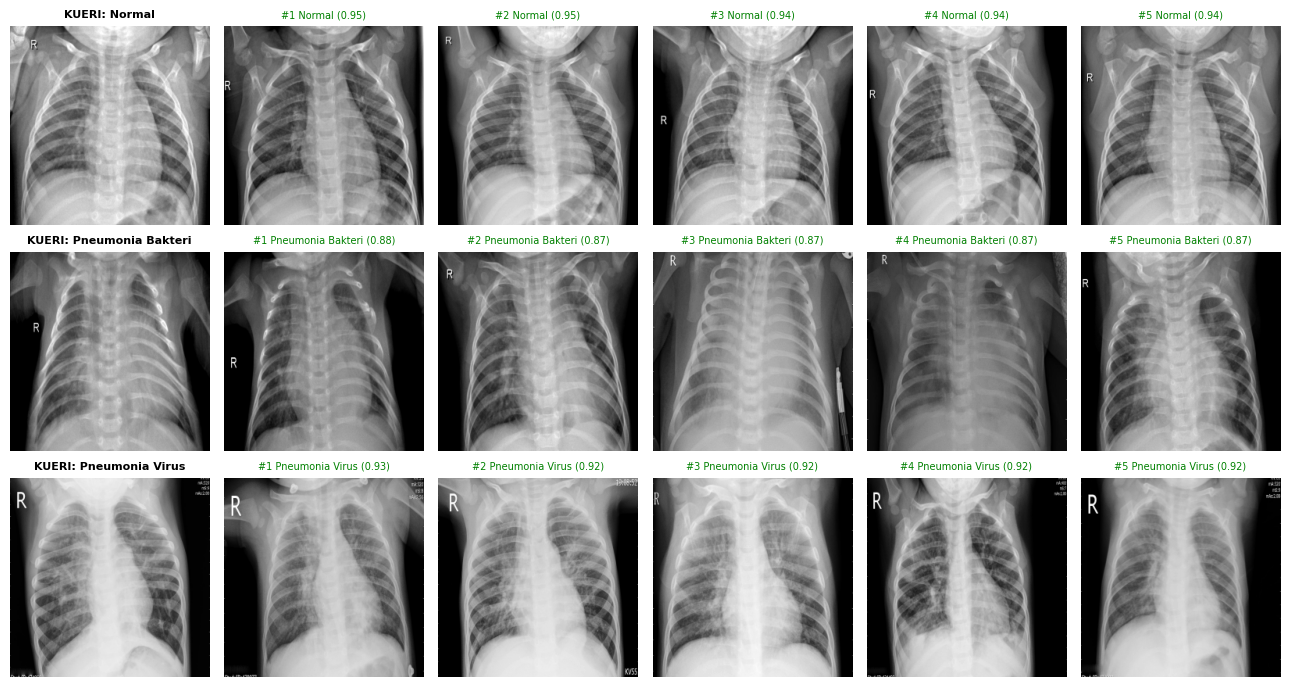

In [6]:
qn, gn = q_emb / np.linalg.norm(q_emb, axis=1, keepdims=True), g_emb / np.linalg.norm(g_emb, axis=1, keepdims=True)
sims = qn @ gn.T
rng = np.random.default_rng(0)
contoh = [rng.choice(np.where(q_lab == c)[0]) for c in range(3)]
fig, axes = plt.subplots(3, 6, figsize=(13, 7))
for r, qi in enumerate(contoh):
    top = np.argsort(-sims[qi])[:5]
    axes[r, 0].imshow(Image.open(DATA_DIR / "cache" / cache_sub / test.cache_name[qi]), cmap="gray")
    axes[r, 0].set_title(f"KUERI: {NAMA_KELAS[CLASSES[q_lab[qi]]]}", fontsize=8, fontweight="bold")
    for j, gi in enumerate(top):
        ok = g_lab[gi] == q_lab[qi]
        axes[r, j + 1].imshow(Image.open(DATA_DIR / "cache" / cache_sub / train.cache_name[gi]), cmap="gray")
        axes[r, j + 1].set_title(f"#{j+1} {NAMA_KELAS[CLASSES[g_lab[gi]]]} ({sims[qi, gi]:.2f})", fontsize=7,
                                 color="green" if ok else "red")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Relevance feedback (Rocchio)
Pengguna menandai 10 hasil teratas sebagai relevan atau tidak (disimulasikan memakai label galeri), lalu kueri
diperbarui: **q' = 1,0·q + 0,75·rata-rata(relevan) − 0,25·rata-rata(tidak relevan)**, dan pencarian diulang.

In [7]:
def rocchio(q, g, gl, ql, k=10, rounds=1, a=1.0, b=0.75, c=0.25):
    q = q / np.linalg.norm(q, axis=1, keepdims=True); g = g / np.linalg.norm(g, axis=1, keepdims=True)
    for _ in range(rounds):
        top = np.argsort(-(q @ g.T), axis=1)[:, :k]
        rel = gl[top] == ql[:, None]
        new = []
        for i in range(len(q)):
            v = a * q[i]
            if rel[i].any(): v = v + b * g[top[i][rel[i]]].mean(0)
            if (~rel[i]).any(): v = v - c * g[top[i][~rel[i]]].mean(0)
            new.append(v)
        q = np.stack(new); q = q / np.linalg.norm(q, axis=1, keepdims=True)
    return q

rf = []
for nama, putaran in (("Tanpa feedback", 0), ("Rocchio 1 putaran", 1), ("Rocchio 2 putaran", 2)):
    qq = rocchio(q_emb, g_emb, g_lab, q_lab, rounds=putaran) if putaran else q_emb
    m, pc = retrieval_metrics(qq, q_lab, g_emb, g_lab)
    rf.append({"Kondisi": nama, "P@10": m["P@10"], "mAP": m["mAP"], "mAP Virus": pc["Pneumonia Virus"]})
pd.DataFrame(rf).round(2)

,Kondisi,P@10,mAP,mAP Virus
0,Tanpa feedback,80.10,81.85,67.09
1,Rocchio 1 putaran,85.09,84.26,70.94
2,Rocchio 2 putaran,87.79,85.55,73.25


## 6. Ringkasan eksperimen pendukung

In [8]:
print("Fitur pretrained ImageNet tanpa fine-tuning (pendekatan referensi utama 2):")
display((pd.read_csv(OUTPUTS / "extra" / "pretrained_retrieval.csv").set_index("Model") * 100).round(1))
print("Pengaruh cara pembagian data (uji kebocoran):")
lk = pd.read_csv(OUTPUTS / "extra" / "leakage_comparison.csv")
display(lk.set_index(["Model", "Pembagian data"]).mul(100).round(1))

Fitur pretrained ImageNet tanpa fine-tuning (pendekatan referensi utama 2):


,P@1,P@5,P@10,mAP@10,mAP,mAP Virus
Model,,,,,,
MobileNetV2,71.4,71.0,70.0,76.8,54.1,34.8
EfficientNet-B0,69.5,69.0,67.5,74.9,51.9,32.6
DenseNet121,71.0,68.8,68.0,75.3,52.5,33.8


Pengaruh cara pembagian data (uji kebocoran):


Akurasi  Macro F1  Macro AUC  \
Model           Pembagian data                                              
MobileNetV2     Per pasien (penelitian ini)     80.6      80.7       91.4   
                Acak per citra                  83.5      82.4       94.0   
EfficientNet-B0 Per pasien (penelitian ini)     81.4      81.9       93.0   
                Acak per citra                  82.8      82.0       94.5   

                                             P@10   mAP  
Model           Pembagian data                           
MobileNetV2     Per pasien (penelitian ini)  80.3  79.0  
                Acak per citra               81.0  77.4  
EfficientNet-B0 Per pasien (penelitian ini)  81.8  80.8  
                Acak per citra               81.1  79.0

## Kesimpulan
- Kelas normal dikenali hampir sempurna; kesalahan terbesar terjadi antara pneumonia bakteri dan virus.
- *Fine-tuning* meningkatkan mAP temu kembali sekitar 25–29 poin dibandingkan fitur *pretrained*.
- Relevance feedback meningkatkan P@10 dan mAP lebih lanjut.
- Augmentasi dan CLAHE tidak memberi peningkatan yang konsisten (perubahan setara variasi antar-seed).